# Spatio-Temporal Graph Neural Network (ST-GNN ChebConv)

This notebook trains and evaluates a Spatio-Temporal Graph Neural Network (ST-GNN) using Chebyshev spectral convolutions on the spatial electrode graph to decode binocular rivalry states (Congruent vs. Incongruent Pure).

### Spatio-Temporal Graph Neural Network (ST-GNN) Pipeline

The ST-GNN extracts spectral band features (theta 5-7 Hz and alpha 8-12 Hz) across sliding windows, constructing graph signals over a spatial adjacency matrix derived from 3D electrode coordinates. Chebyshev graph convolutions model spatial propagation, followed by a 1D temporal CNN and classification.

In [1]:
import sys
import warnings
from pathlib import Path
import matplotlib.pyplot as plt
%pip install -q mne shap
import mne
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from scipy.stats import ttest_1samp, wilcoxon
from mne.stats import fdr_correction
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, precision_recall_curve, auc

try:
    NOTEBOOK_DIR = Path(__file__).resolve().parent
except NameError:
    NOTEBOOK_DIR = Path.cwd()
SRC_DIR = (
    Path("/content/drive/MyDrive/TFG_Nils_2026/03_Codi")
    if "google.colab" in sys.modules
    else NOTEBOOK_DIR.parent.parent / "src"
)

try:
    from google.colab import drive
    IN_COLAB = True
    drive.mount("/content/drive")
except ImportError:
    IN_COLAB = False

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from br_analysis import (
    BinaryTaskConfig,
    RawEpochSpec,
    detect_project_paths,
    load_raw_epoch_dataset,
    get_task_config,
    electrode_distance_adjacency,
    temporal_band_features
)
from br_analysis.torch_training import (
    TorchTrainConfig,
    cross_validate_torch_model,
    plot_fold_metrics,
    plot_torch_history,
    run_torch_epochs_grid,
    run_torch_time_map,
)
from br_analysis.torch_models import STGNNChebConv

warnings.filterwarnings("ignore", category=RuntimeWarning)
mne.set_log_level("WARNING")
RANDOM_SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cuda":
    torch.backends.cudnn.benchmark = True
    print(f"Using CUDA GPU: {torch.cuda.get_device_name(0)}")
else:
    print("CUDA is not available; using CPU.")


[notice] A new release of pip is available: 25.2 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
CUDA is not available; using CPU.


## Task And Output Paths

In [2]:
TASK_TAG = "c_vs_ip_stgnn"
paths = detect_project_paths("c_vs_i_stgnn", in_colab=IN_COLAB)
SELECTED_SUBJECTS_CSV = paths.analysis_root / "exploration" / "tables" / "subjectes_seleccionats.csv"
MAX_SUBJECTS = 24

task = get_task_config("c_vs_ip", paths.analysis_root, name=TASK_TAG, analysis_window=(0.0, 1.5))

print(f"Project: {paths.project_dir}")
print(f"Data: {paths.data_dir}")
print(f"Results: {paths.analysis_dir}")

Project: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026
Data: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\02_Data\01_Preprocessed_epochs
Results: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\c_vs_i_stgnn


## Load Epochs And Build Graph Features

Selected subjects to load: 24
Total samples: 5870 | Congruent=2935 | Incongruent_Pure=2935
Loaded subjects: 24 | Channels: 60
Raw X: (5870, 60, 192) (trials, channels, times)
Graph X: (5870, 10, 60, 2) (trials, windows, nodes, bands)
Bands: ['theta', 'alpha']
Adjacency: (60, 60), density=1.000


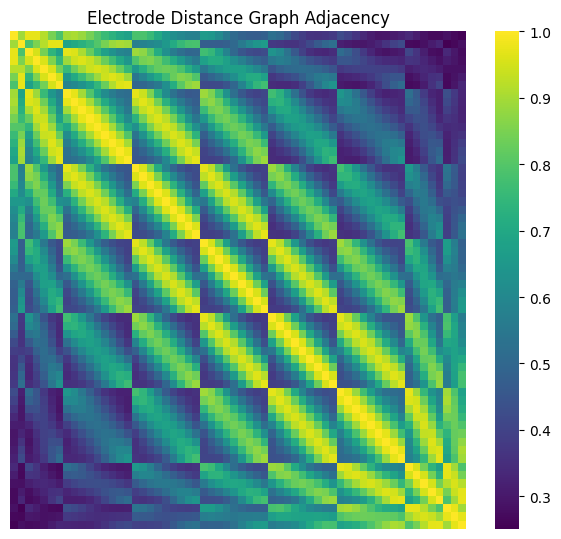

In [3]:
spec = RawEpochSpec(picks=None, bandpass=(4.0, 13.0), resample_sfreq=128.0)
dataset = load_raw_epoch_dataset(paths, task, spec)
X_raw = np.asarray(dataset.X, dtype=np.float32)
y = np.asarray(dataset.y, dtype=np.int64)
subjects = np.asarray(dataset.subjects, dtype=object)
SUBJECT_ID = "P057"
ch_names = list(dataset.channel_names)
sfreq = 128.0

# Build graph spatiotemporal features
bands = {"theta": (5.0, 7.0), "alpha": (8.0, 12.0)}
X_graph, window_centers, band_names = temporal_band_features(
    X_raw,
    sfreq,
    bands=bands,
    window_sec=0.500,
    step_sec=0.100,
    mode="of",
)
adjacency = electrode_distance_adjacency(ch_names, threshold=0.35)

print(f"Raw X: {X_raw.shape} (trials, channels, times)")
print(f"Graph X: {X_graph.shape} (trials, windows, nodes, bands)")
print(f"Bands: {band_names}")
print(f"Adjacency: {adjacency.shape}, density={(adjacency > 0).mean():.3f}")

# Plot adjacency matrix
plt.figure(figsize=(6, 5.5))
sns.heatmap(adjacency, xticklabels=False, yticklabels=False, cmap="viridis")
plt.title("Electrode Distance Graph Adjacency")
plt.tight_layout()
plt.savefig(paths.figures_dir / f"adjacency_{TASK_TAG}.png", dpi=160, bbox_inches="tight")
plt.show()

## ST-GNN Model Definition & Configuration

In [4]:
n_windows = X_graph.shape[1]
n_nodes = X_graph.shape[2]
n_features = X_graph.shape[3]


def make_model():
    return STGNNChebConv(
        n_nodes=n_nodes,
        in_features=n_features,
        adjacency=adjacency,
        n_classes=2,
        cheb_hidden=32,
        temporal_hidden=64,
        K=3,
        dropout=0.4,
    )


train_cfg = TorchTrainConfig(
    epochs=60,
    batch_size=32,
    lr=1e-3,
    weight_decay=1e-4,
    patience=12,
    n_splits=5,
    val_size=0.2,
    random_seed=RANDOM_SEED,
    device=DEVICE,
    progress=True,
)

## 3. Cohort-Wide Training

We train the ST-GNN model across all 24 subjects individually and cache the results.

In [5]:
cohort_metrics_path = paths.tables_dir / f"cohort_cv_metrics_{TASK_TAG}.csv"
cohort_fold_metrics_path = paths.tables_dir / f"cohort_fold_metrics_{TASK_TAG}.csv"
subject_ids = pd.unique(subjects).tolist()

if cohort_metrics_path.exists() and cohort_fold_metrics_path.exists():
    print("Loading ST-GNN cohort metrics from cache...")
    df_cohort = pd.read_csv(cohort_metrics_path)
    df_cohort_folds = pd.read_csv(cohort_fold_metrics_path)
else:
    print("Running ST-GNN cohort-wide cross-validation ...")
    cohort_results = []
    cohort_fold_results = []

    silent_cfg = TorchTrainConfig(
        epochs=train_cfg.epochs,
        batch_size=train_cfg.batch_size,
        lr=train_cfg.lr,
        weight_decay=train_cfg.weight_decay,
        patience=train_cfg.patience,
        n_splits=train_cfg.n_splits,
        val_size=train_cfg.val_size,
        random_seed=train_cfg.random_seed,
        device=train_cfg.device,
        progress=False,
    )

    for sub in subject_ids:
        print(f"Training subject {sub}...")
        stgnn_metrics, _ = cross_validate_torch_model(
            X_graph,
            y,
            make_model,
            silent_cfg,
            subjects=subjects,
            subject_id=sub,
            save_weights_dir=paths.cache_dir,
            weights_prefix=f"{TASK_TAG}_sub{sub}",
            load_weights=True,
        )

        cohort_results.append(
            {
                "subject": sub,
                "stgnn_acc": stgnn_metrics["test_acc"].mean(),
                "stgnn_auc": stgnn_metrics["test_auc"].mean(),
                "stgnn_bal_acc": stgnn_metrics["test_balanced_acc"].mean(),
            }
        )

        for idx, row in stgnn_metrics.iterrows():
            cohort_fold_results.append(
                {
                    "subject": sub,
                    "model": "ST-GNN",
                    "fold": int(row["fold"]),
                    "test_acc": row["test_acc"],
                    "test_auc": row["test_auc"],
                    "test_balanced_acc": row["test_balanced_acc"],
                }
            )

    df_cohort = pd.DataFrame(cohort_results)
    df_cohort.to_csv(cohort_metrics_path, index=False)
    df_cohort_folds = pd.DataFrame(cohort_fold_results)
    df_cohort_folds.to_csv(cohort_fold_metrics_path, index=False)
    print(f"Saved cohort metrics to: {cohort_metrics_path}")

print(df_cohort.describe())

Running ST-GNN cohort-wide cross-validation ...
Training subject P057...
Filtering to subject P057: 240 epochs
Using torch device: cpu
Fold 1: acc=0.250, bal_acc=0.500, auc=0.597 | fold_time=00:00:05 elapsed_cv=00:00:05 eta_cv=00:00:21
Fold 2: acc=0.850, bal_acc=0.500, auc=0.686 | fold_time=00:00:01 elapsed_cv=00:00:06 eta_cv=00:00:10
Fold 3: acc=0.575, bal_acc=0.500, auc=0.379 | fold_time=00:00:02 elapsed_cv=00:00:09 eta_cv=00:00:06
Fold 4: acc=0.875, bal_acc=0.500, auc=0.669 | fold_time=00:00:02 elapsed_cv=00:00:12 eta_cv=00:00:03
Fold 5: acc=0.775, bal_acc=0.542, auc=0.451 | fold_time=00:00:04 elapsed_cv=00:00:16 eta_cv=00:00:00

OVERALL CROSS-VALIDATION CLASSIFICATION REPORT (AGGREGATED)
              precision    recall  f1-score   support

           0       0.64      0.89      0.75       110
           1       0.74      0.39      0.51        90

    accuracy                           0.67       200
   macro avg       0.69      0.64      0.63       200
weighted avg       0.69    

## 4. Single-Subject Detailed Performance Comparison (P057)

=== ST-GNN Classification Report (Subject P057) ===
                  precision    recall  f1-score   support

       Congruent       0.64      0.89      0.75       110
Incongruent_Pure       0.74      0.39      0.51        90

        accuracy                           0.67       200
       macro avg       0.69      0.64      0.63       200
    weighted avg       0.69      0.67      0.64       200



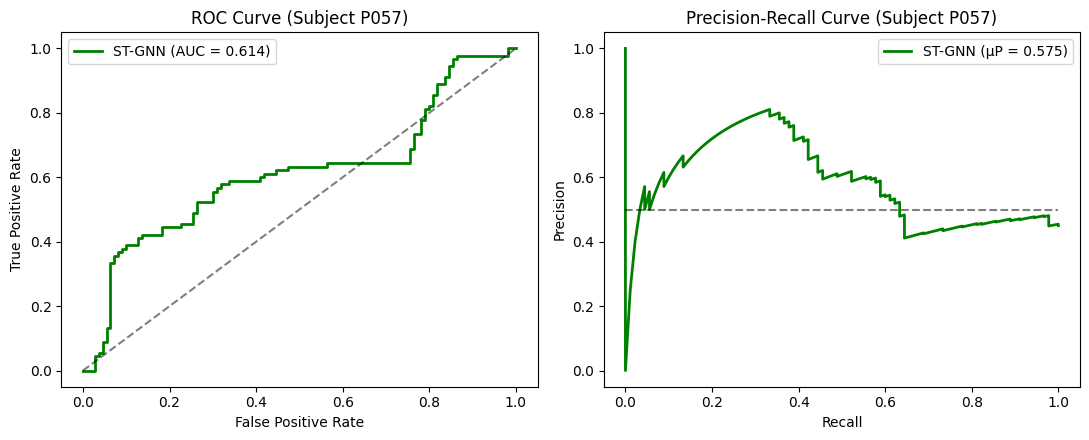

In [17]:
from br_analysis.torch_training import build_dataloader, standardize_train_test, _evaluate, temporal_stratified_splits

device = torch.device(DEVICE)
splits = list(temporal_stratified_splits(y[subjects == SUBJECT_ID], train_cfg.n_splits))
X_sub = X_graph[subjects == SUBJECT_ID]
y_sub = y[subjects == SUBJECT_ID]

probs = []
y_true_all = []

for fold, (train_idx, test_idx) in enumerate(splits, start=1):
    _, X_test = standardize_train_test(X_sub[train_idx], X_sub[test_idx])
    y_test = y_sub[test_idx]
    y_true_all.extend(y_test)

    model = make_model().to(device)
    model.load_state_dict(
        torch.load(paths.cache_dir / f"{TASK_TAG}_sub{SUBJECT_ID}_fold{fold}.pt", map_location=device)
    )
    loader = build_dataloader(X_test, y_test, batch_size=train_cfg.batch_size, shuffle=False, device=device)
    _, _, _, p = _evaluate(model, loader, device)
    probs.extend(p)

y_true_all = np.array(y_true_all)
probs = np.array(probs)
preds = (probs >= 0.5).astype(int)

print("=== ST-GNN Classification Report (Subject P057) ===")
print(classification_report(y_true_all, preds, target_names=[task.class_0, task.class_1]))

# Plot ROC/PR curves
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(11, 4.5))
fpr, tpr, _ = roc_curve(y_true_all, probs)
ax_roc.plot(fpr, tpr, label=f"ST-GNN (AUC = {auc(fpr, tpr):.3f})", color="green", linewidth=2)
ax_roc.plot([0, 1], [0, 1], "k--", alpha=0.5)
ax_roc.set_title("ROC Curve (Subject P057)")
ax_roc.set_xlabel("False Positive Rate")
ax_roc.set_ylabel("True Positive Rate")
ax_roc.legend()

prec, rec, _ = precision_recall_curve(y_true_all, probs)
ax_pr.plot(rec, prec, label=f"ST-GNN (μP = {auc(rec, prec):.3f})", color="green", linewidth=2)
ax_pr.plot([0, 1], [0.5, 0.5], "k--", alpha=0.5)
ax_pr.set_title("Precision-Recall Curve (Subject P057)")
ax_pr.set_xlabel("Recall")
ax_pr.set_ylabel("Precision")
ax_pr.legend()

plt.tight_layout()
plt.savefig(paths.figures_dir / f"roc_pr_{TASK_TAG}_P057.png", dpi=180, bbox_inches="tight")
plt.show()

## 5. Single-Subject Fold Analysis & Saliency Mapping (P057)

We statistically evaluate the 5 CV folds against the 50% chance level and extract absolute gradients to map spatiotemporal node importances.

In [7]:
from scipy.stats import ttest_1samp, wilcoxon

metrics_sub = df_cohort_folds[df_cohort_folds["subject"] == SUBJECT_ID].copy()
acc_folds = metrics_sub["test_acc"].values

t_stat, p_val_t = ttest_1samp(acc_folds, 0.5)
w_stat, p_val_w = wilcoxon(acc_folds - 0.5)

print("=== P057 Fold Accuracies ===")
print(f"Accuracies: {acc_folds}")
print(f"One-sample t-test (vs 0.5): t-statistic = {t_stat:.3f}, p-value = {p_val_t:.4f}")
print(f"One-sample Wilcoxon (vs 0.5): W-statistic = {w_stat:.3f}, p-value = {p_val_w:.4f}")

=== P057 Fold Accuracies ===
Accuracies: [0.25  0.85  0.575 0.875 0.775]
One-sample t-test (vs 0.5): t-statistic = 1.418, p-value = 0.2291
One-sample Wilcoxon (vs 0.5): W-statistic = 2.000, p-value = 0.1875


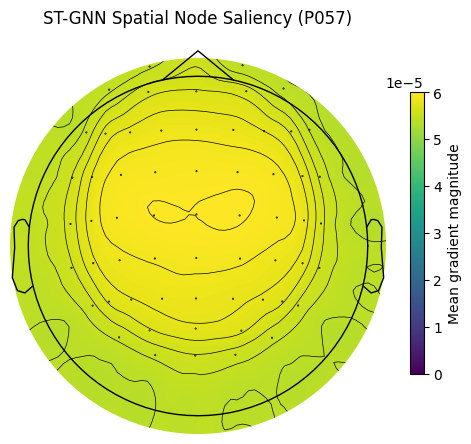

C:\Users\nils\AppData\Local\Temp\ipykernel_22292\1524154793.py:57: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


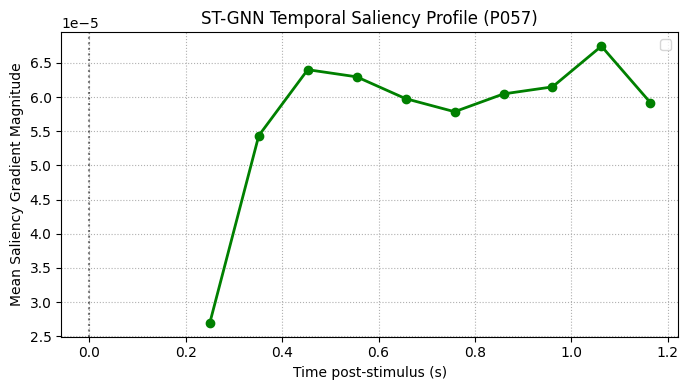

In [8]:
# Compute P057 Graph Node Saliency (gradients w.r.t nodes and windows)
device = torch.device(DEVICE)
splits = list(temporal_stratified_splits(y[subjects == SUBJECT_ID], train_cfg.n_splits))
X_sub = X_graph[subjects == SUBJECT_ID]
y_sub = y[subjects == SUBJECT_ID]

saliencies = []
for fold, (train_idx, test_idx) in enumerate(splits, start=1):
    _, X_test = standardize_train_test(X_sub[train_idx], X_sub[test_idx])
    y_test = y_sub[test_idx]

    # Filter conflict trials (class 1)
    idx_c1 = y_test == 1
    if not np.any(idx_c1):
        continue

    model = make_model().to(device)
    model.load_state_dict(
        torch.load(paths.cache_dir / f"{TASK_TAG}_sub{SUBJECT_ID}_fold{fold}.pt", map_location=device)
    )
    model.eval()

    X_tensor = torch.from_numpy(X_test[idx_c1]).to(device)
    X_tensor.requires_grad_()
    logits = model(X_tensor)
    probs_out = torch.softmax(logits, dim=1)
    score = probs_out[:, 1].sum()
    model.zero_grad()
    score.backward()

    saliency = X_tensor.grad.abs().cpu().numpy()  # Shape: (trials, windows, nodes, features)
    saliencies.append(saliency.mean(axis=0))  # Mean over trials

mean_saliency_p057 = np.mean(saliencies, axis=0)  # Shape: (windows, nodes, features)
spatial_imp = mean_saliency_p057.mean(axis=(0, 2))  # Shape: (nodes,)
temporal_imp = mean_saliency_p057.mean(axis=(1, 2))  # Shape: (windows,)

# Plot Spatial Node Saliency
fig, ax = plt.subplots(figsize=(5, 5))
montage = mne.channels.make_standard_montage("standard_1005")
info = mne.create_info(ch_names=ch_names, sfreq=128.0, ch_types="eeg")
info.set_montage(montage, on_missing="ignore")
im, _ = mne.viz.plot_topomap(spatial_imp, info, axes=ax, cmap="viridis", show=False)
ax.set_title("ST-GNN Spatial Node Saliency (P057)")
fig.colorbar(im, ax=ax, shrink=0.6, label="Mean gradient magnitude")
plt.tight_layout()
plt.savefig(paths.figures_dir / f"saliency_spatial_P057_{TASK_TAG}.png", dpi=180, bbox_inches="tight")
plt.show()

# Plot Temporal Saliency Profile
plt.figure(figsize=(7, 4))
plt.plot(window_centers, temporal_imp, "o-", color="green", linewidth=2)
plt.axvline(0.0, color="black", alpha=0.5, linestyle=":")
plt.title("ST-GNN Temporal Saliency Profile (P057)")
plt.xlabel("Time post-stimulus (s)")
plt.ylabel("Mean Saliency Gradient Magnitude")
plt.legend()
plt.grid(True, linestyle=":")
plt.tight_layout()
plt.savefig(paths.figures_dir / f"saliency_temporal_P057_{TASK_TAG}.png", dpi=180, bbox_inches="tight")
plt.show()

### 5.4 SHAP Explainability (Subject P057)

We use SHAP (SHapley Additive exPlanations) via `shap.GradientExplainer` to compute feature attributions for electrode channels and temporal graph windows.

DEBUG - Forma original del tensor SHAP: (10, 10, 60, 2, 2)


C:\Users\nils\AppData\Local\Temp\ipykernel_22292\383685921.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.9, 1])


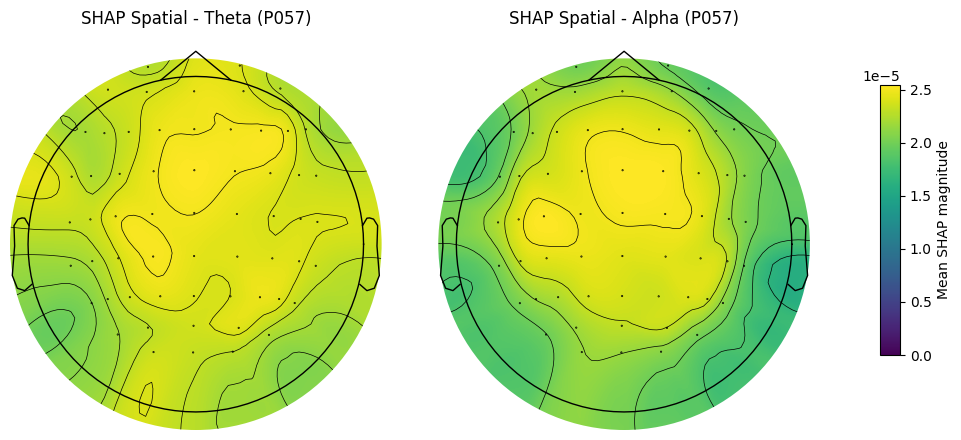

C:\Users\nils\AppData\Local\Temp\ipykernel_22292\383685921.py:98: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax_temp.legend()


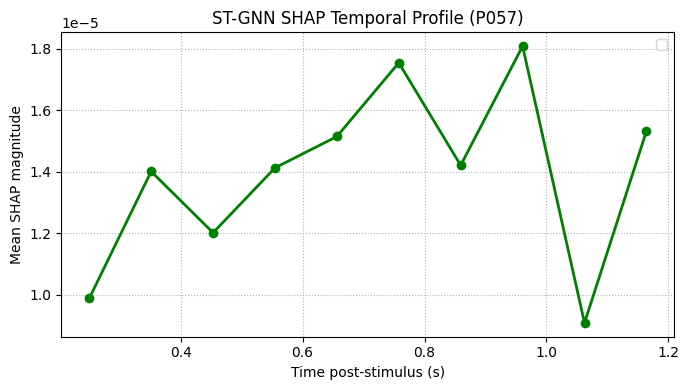

In [9]:
import shap
import torch
import numpy as np
import matplotlib.pyplot as plt
import mne

device = torch.device(DEVICE)
splits = list(temporal_stratified_splits(y[subjects == SUBJECT_ID], train_cfg.n_splits))
X_sub = X_graph[subjects == SUBJECT_ID]
y_sub = y[subjects == SUBJECT_ID]
train_idx, test_idx = splits[0]

_, X_test = standardize_train_test(X_sub[train_idx], X_sub[test_idx])
y_test = y_sub[test_idx]

# Filter conflict trials
idx_c1 = y_test == 1
if np.any(idx_c1):
    model = make_model().to(device)
    model.load_state_dict(torch.load(paths.cache_dir / f"{TASK_TAG}_sub{SUBJECT_ID}_fold1.pt", map_location=device))
    model.eval()

    bg_tensor = torch.from_numpy(X_test[: min(len(X_test), 50)]).to(device)
    test_tensor = torch.from_numpy(X_test[idx_c1][: min(np.sum(idx_c1), 10)]).to(device)

    explainer = shap.GradientExplainer(model, bg_tensor)
    shap_values = explainer.shap_values(test_tensor)

    if isinstance(shap_values, list):
        shap_class1 = shap_values[1]
    else:
        shap_class1 = shap_values

    # 1. Traiem l'absolut dels valors SHAP
    shap_abs = np.abs(shap_class1)
    print(f"DEBUG - Forma original del tensor SHAP: {shap_abs.shape}")

    # 2. Busquem dinàmicament on estan els elèctrodes (60) i les bandes (2)
    shape_list = list(shap_abs.shape)
    idx_nodes = shape_list.index(60)
    # Busquem l'índex del "2" (començant pel final per no confondre's amb el batch size si casualment és 2)
    idx_bands = len(shape_list) - 1 - shape_list[::-1].index(2)

    # 3. Fem la mitjana de TOTA la resta de dimensions (assajos, finestres temporals, etc.)
    axes_to_collapse = tuple(i for i in range(len(shape_list)) if i not in (idx_nodes, idx_bands))
    shap_spatial_2d = shap_abs.mean(axis=axes_to_collapse)

    # Assegurem-nos que l'estructura queda com a (60 elèctrodes, 2 bandes)
    if shap_spatial_2d.shape[0] == 2:
        shap_spatial_2d = shap_spatial_2d.T

    # 4. Extraiem les bandes i forcem l'aplanament a 1D amb .flatten()
    shap_spatial_theta = shap_spatial_2d[:, 0].flatten()  # Ara serà exactament (60,)
    shap_spatial_alpha = shap_spatial_2d[:, 1].flatten()  # Ara serà exactament (60,)

    # Comprovació de seguretat abans de dibuixar
    assert shap_spatial_theta.shape == (60,), f"Error: Theta continua sent {shap_spatial_theta.shape}"
    assert shap_spatial_alpha.shape == (60,), f"Error: Alfa continua sent {shap_spatial_alpha.shape}"

    # 5. Avaluació Temporal (per a la gràfica de línies, col·lapsem espai i freqüència)
    idx_time = next(i for i in range(len(shape_list)) if i not in (0, idx_nodes, idx_bands))
    axes_for_temporal = tuple(i for i in range(len(shape_list)) if i != idx_time)
    shap_temporal = shap_abs.mean(axis=axes_for_temporal)

    # === PLOTS ===
    fig_topo, axes_topo = plt.subplots(1, 2, figsize=(10, 4.5))
    ax_spat_theta, ax_spat_alpha = axes_topo

    info = mne.create_info(ch_names=ch_names, sfreq=128.0, ch_types="eeg")
    info.set_montage(montage, on_missing="ignore")

    # Topomap 1: Banda Theta
    im1, _ = mne.viz.plot_topomap(shap_spatial_theta, info, axes=ax_spat_theta, cmap="viridis", show=False)
    ax_spat_theta.set_title(f"SHAP Spatial - Theta ({SUBJECT_ID})")

    # Topomap 2: Banda Alfa
    im2, _ = mne.viz.plot_topomap(shap_spatial_alpha, info, axes=ax_spat_alpha, cmap="viridis", show=False)
    ax_spat_alpha.set_title(f"SHAP Spatial - Alpha ({SUBJECT_ID})")

    # Colorbar posicionada a la dreta dels dos mapes
    cbar_ax = fig_topo.add_axes([0.92, 0.2, 0.02, 0.6])
    fig_topo.colorbar(im1, cax=cbar_ax, label="Mean SHAP magnitude")

    plt.tight_layout(rect=[0, 0, 0.9, 1])
    plt.savefig(
        paths.figures_dir / f"shap_explainability_spatial_P{SUBJECT_ID}_{TASK_TAG}.png", dpi=180, bbox_inches="tight"
    )
    plt.show()

    # Grafica Temporal en figura separada
    fig_temp, ax_temp = plt.subplots(1, 1, figsize=(7, 4))
    ax_temp.plot(window_centers, shap_temporal, "o-", color="green", linewidth=2)
    ax_temp.set_title(f"ST-GNN SHAP Temporal Profile ({SUBJECT_ID})")
    ax_temp.set_xlabel("Time post-stimulus (s)")
    ax_temp.set_ylabel("Mean SHAP magnitude")
    ax_temp.legend()
    ax_temp.grid(True, linestyle=":")

    plt.tight_layout()
    plt.savefig(
        paths.figures_dir / f"shap_explainability_temporal_P{SUBJECT_ID}_{TASK_TAG}.png", dpi=180, bbox_inches="tight"
    )
    plt.show()

## 6. Cohort-Level Group Performance, Error Asymmetry & Saliency

=== Cohort Performance Stats (vs 0.5) ===
Mean Acc: 0.5151 | Std Acc: 0.0466
t-test: t-stat=1.587, p-val=0.1262
Wilcoxon: W-stat=108.000, p-val=0.2405


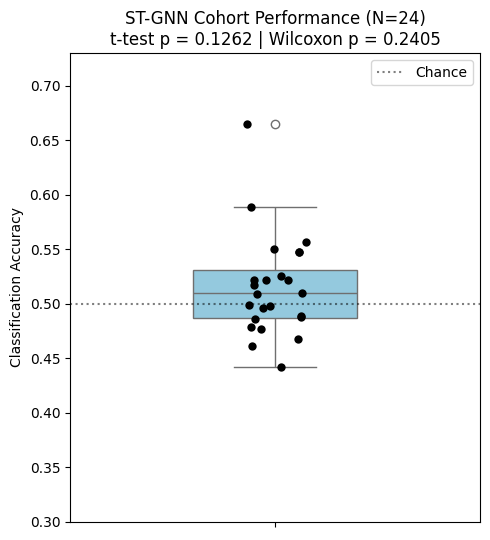

In [10]:
# Plot Group Performance Boxplot
t_stat, p_val_t = ttest_1samp(df_cohort["stgnn_acc"], 0.5)
w_stat, p_val_w = wilcoxon(df_cohort["stgnn_acc"] - 0.5)

print("=== Cohort Performance Stats (vs 0.5) ===")
print(f"Mean Acc: {df_cohort['stgnn_acc'].mean():.4f} | Std Acc: {df_cohort['stgnn_acc'].std():.4f}")
print(f"t-test: t-stat={t_stat:.3f}, p-val={p_val_t:.4f}")
print(f"Wilcoxon: W-stat={w_stat:.3f}, p-val={p_val_w:.4f}")

plt.figure(figsize=(5, 5.5))
sns.boxplot(y=df_cohort["stgnn_acc"], color="skyblue", width=0.4)
sns.stripplot(y=df_cohort["stgnn_acc"], color="black", size=6, jitter=0.08)
plt.axhline(0.5, color="black", linestyle=":", alpha=0.5, label="Chance")
plt.title(f"ST-GNN Cohort Performance (N={len(df_cohort)})\nt-test p = {p_val_t:.4f} | Wilcoxon p = {p_val_w:.4f}")
plt.ylabel("Classification Accuracy")
plt.ylim(0.3, 0.73)
plt.legend()
plt.tight_layout()
plt.savefig(paths.figures_dir / f"cohort_performance_boxplot_{TASK_TAG}.png", dpi=200, bbox_inches="tight")
plt.show()

Extracting cohort predictions across all subjects and folds...


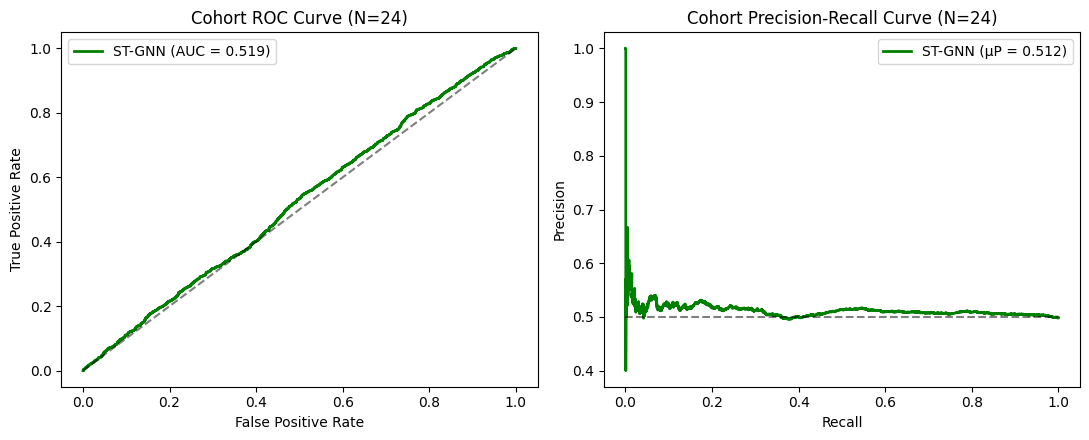

In [18]:
# Compute cohort-wide aggregated ROC/PR curves
all_y_true = []
all_probs = []
subject_y_trues = {}
subject_y_probs = {}

print("Extracting cohort predictions across all subjects and folds...")
for sub in subject_ids:
    splits = list(temporal_stratified_splits(y[subjects == sub], train_cfg.n_splits))
    X_sub = X_graph[subjects == sub]
    y_sub = y[subjects == sub]

    sub_y_true = []
    sub_y_prob = []

    for fold, (train_idx, test_idx) in enumerate(splits, start=1):
        _, X_test = standardize_train_test(X_sub[train_idx], X_sub[test_idx])
        y_test = y_sub[test_idx]

        weights_path = paths.cache_dir / f"{TASK_TAG}_sub{sub}_fold{fold}.pt"
        if weights_path.exists():
            model = make_model().to(device)
            model.load_state_dict(torch.load(weights_path, map_location=device))
            model.eval()

            loader = build_dataloader(X_test, y_test, batch_size=train_cfg.batch_size, shuffle=False, device=device)
            _, _, y_true_arr, p = _evaluate(model, loader, device)
            all_y_true.extend(y_true_arr)
            all_probs.extend(p)
            sub_y_true.extend(y_true_arr)
            sub_y_prob.extend(p)

    if len(sub_y_true) > 0:
        subject_y_trues[sub] = np.array(sub_y_true)
        subject_y_probs[sub] = np.array(sub_y_prob)

all_y_true = np.array(all_y_true)
all_probs = np.array(all_probs)
all_preds = (all_probs >= 0.5).astype(int)

fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(11, 4.5))
fpr, tpr, _ = roc_curve(all_y_true, all_probs)
ax_roc.plot(fpr, tpr, label=f"ST-GNN (AUC = {auc(fpr, tpr):.3f})", color="green", linewidth=2)
ax_roc.plot([0, 1], [0, 1], "k--", alpha=0.5)
ax_roc.set_title(f"Cohort ROC Curve (N={len(subject_ids)})")
ax_roc.set_xlabel("False Positive Rate")
ax_roc.set_ylabel("True Positive Rate")
ax_roc.legend()

prec, rec, _ = precision_recall_curve(all_y_true, all_probs)
ax_pr.plot(rec, prec, label=f"ST-GNN (μP = {auc(rec, prec):.3f})", color="green", linewidth=2)
ax_pr.plot([0, 1], [0.5, 0.5], "k--", alpha=0.5)
ax_pr.set_title(f"Cohort Precision-Recall Curve (N={len(subject_ids)})")
ax_pr.set_xlabel("Recall")
ax_pr.set_ylabel("Precision")
ax_pr.legend()

plt.tight_layout()
plt.savefig(paths.figures_dir / f"cohort_roc_pr_{TASK_TAG}.png", dpi=200, bbox_inches="tight")
plt.show()

In [25]:
# 1. Standard aggregated reports (all folds combined)
reports = []
for sub in subject_y_trues.keys():
    sub_y_true = subject_y_trues[sub]
    sub_y_pred = (subject_y_probs[sub] >= 0.5).astype(int)
    rep = classification_report(sub_y_true, sub_y_pred, target_names=[task.class_0, task.class_1], output_dict=True)
    reports.append(rep)

avg_report = {}
metrics_keys = ["precision", "recall", "f1-score", "support"]
class_keys = [task.class_0, task.class_1, "macro avg", "weighted avg"]
for ck in class_keys:
    avg_report[ck] = {}
    for mk in metrics_keys:
        avg_report[ck][mk] = np.mean([r[ck][mk] for r in reports])
avg_report["accuracy"] = np.mean([r["accuracy"] for r in reports])

print("==========================================================")
print("=== AVERAGE CLASSIFICATION REPORT (ALL FOLDS COMBINED) ===")
print("==========================================================")
print("--- ST-GNN (All Folds) ---")
print(pd.DataFrame(avg_report).T)


# 2. Extract and compute classification reports specifically for FOLD 5 (representing maximum training data)
print("\n\n" + "=" * 58)
print("=== FOLD 5 CLASSIFICATION REPORT (MAX TRAINING TRIALS) ===")
print("=" * 58)

reports_f5 = []

for sub in subject_ids:
    splits = list(temporal_stratified_splits(y[subjects == sub], train_cfg.n_splits))
    X_sub = X_graph[subjects == sub]
    y_sub = y[subjects == sub]

    # We focus on Fold 5 (index 4 of the splits)
    train_idx, test_idx = splits[4]

    _, X_test = standardize_train_test(X_sub[train_idx], X_sub[test_idx])
    y_test = y_sub[test_idx]

    # Fold 5 weights
    weights_path = paths.cache_dir / f"{TASK_TAG}_sub{sub}_fold5.pt"
    if weights_path.exists():
        model = make_model().to(device)
        model.load_state_dict(torch.load(weights_path, map_location=device))
        model.eval()
        loader = build_dataloader(X_test, y_test, batch_size=train_cfg.batch_size, shuffle=False, device=device)
        _, _, y_true_arr, p = _evaluate(model, loader, device)
        rep = classification_report(
            y_true_arr,
            (p >= 0.5).astype(int),
            target_names=[task.class_0, task.class_1],
            output_dict=True,
            zero_division=0,
        )
        reports_f5.append(rep)

avg_report_f5 = {}
for ck in class_keys:
    avg_report_f5[ck] = {}
    for mk in metrics_keys:
        avg_report_f5[ck][mk] = np.mean([r[ck][mk] for r in reports_f5])
avg_report_f5["accuracy"] = np.mean([r["accuracy"] for r in reports_f5])

print("--- ST-GNN (Fold 5) ---")
print(pd.DataFrame(avg_report_f5).T)

=== AVERAGE CLASSIFICATION REPORT (ALL FOLDS COMBINED) ===
--- ST-GNN (All Folds) ---
                  precision    recall  f1-score     support
Congruent          0.518692  0.517368  0.501800  102.083333
Incongruent_Pure   0.522187  0.513738  0.497711  101.375000
macro avg          0.520440  0.515553  0.499756  203.458333
weighted avg       0.521200  0.515008  0.499863  203.458333
accuracy           0.515008  0.515008  0.515008    0.515008


=== FOLD 5 CLASSIFICATION REPORT (MAX TRAINING TRIALS) ===
--- ST-GNN (Fold 5) ---
                  precision    recall  f1-score    support
Congruent          0.503574  0.567596  0.495062  20.958333
Incongruent_Pure   0.432740  0.464443  0.419761  19.500000
macro avg          0.468157  0.516019  0.457411  40.458333
weighted avg       0.496920  0.535083  0.480799  40.458333
accuracy           0.535083  0.535083  0.535083   0.535083


=== ST-GNN Cohort Bias Analysis ===
TN: 1228 | FP: 1222 | FN: 1137 | TP: 1296
FP / FN Bias Ratio: 1.075


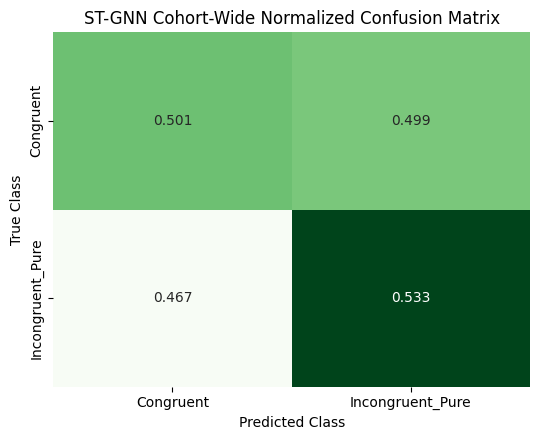

In [13]:
cm = confusion_matrix(all_y_true, all_preds, normalize="true")
tn, fp, fn, tp = confusion_matrix(all_y_true, all_preds).ravel()
bias_ratio = fp / fn if fn > 0 else np.nan

print("=== ST-GNN Cohort Bias Analysis ===")
print(f"TN: {tn} | FP: {fp} | FN: {fn} | TP: {tp}")
print(f"FP / FN Bias Ratio: {bias_ratio:.3f}")

plt.figure(figsize=(5.5, 4.5))
classes = [task.class_0, task.class_1]
sns.heatmap(cm, annot=True, fmt=".3f", cmap="Greens", xticklabels=classes, yticklabels=classes, cbar=False)
plt.title("ST-GNN Cohort-Wide Normalized Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.tight_layout()
plt.savefig(paths.figures_dir / f"cohort_confusion_matrix_{TASK_TAG}.png", dpi=200, bbox_inches="tight")
plt.show()

Computing cohort-wide differential saliency maps (Class 1 - Class 0)... 
FDR Significant Channels (p_FDR < 0.05): []


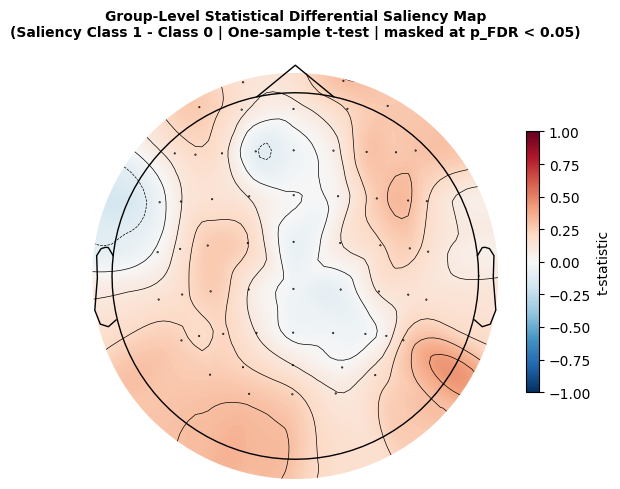

In [30]:
group_diff_spatial = []
print("Computing cohort-wide differential saliency maps (Class 1 - Class 0)... ")
for sub in subject_ids:
    splits = list(temporal_stratified_splits(y[subjects == sub], train_cfg.n_splits))
    X_sub = X_graph[subjects == sub]
    y_sub = y[subjects == sub]

    sub_c1 = []
    sub_c0 = []

    for fold, (train_idx, test_idx) in enumerate(splits, start=1):
        _, X_test = standardize_train_test(X_sub[train_idx], X_sub[test_idx])
        y_test = y_sub[test_idx]

        weights_path = paths.cache_dir / f"{TASK_TAG}_sub{sub}_fold{fold}.pt"
        if weights_path.exists():
            model = make_model().to(device)
            model.load_state_dict(torch.load(weights_path, map_location=device))
            model.eval()

            # Class 1
            idx_c1 = y_test == 1
            if np.any(idx_c1):
                X_tensor = torch.from_numpy(X_test[idx_c1]).to(device)
                X_tensor.requires_grad_()
                logits = model(X_tensor)
                probs_out = torch.softmax(logits, dim=1)
                score = probs_out[:, 1].sum()
                model.zero_grad()
                score.backward()
                saliency_c1 = X_tensor.grad.abs().cpu().numpy()
                sub_c1.append(saliency_c1.mean(axis=0))

            # Class 0
            idx_c0 = y_test == 0
            if np.any(idx_c0):
                X_tensor = torch.from_numpy(X_test[idx_c0]).to(device)
                X_tensor.requires_grad_()
                logits = model(X_tensor)
                probs_out = torch.softmax(logits, dim=1)
                score = probs_out[:, 0].sum()
                model.zero_grad()
                score.backward()
                saliency_c0 = X_tensor.grad.abs().cpu().numpy()
                sub_c0.append(saliency_c0.mean(axis=0))

    if sub_c1 and sub_c0:
        mean_c1 = np.mean(sub_c1, axis=0)
        mean_c0 = np.mean(sub_c0, axis=0)

        mean_c1_norm = mean_c1 / np.max(mean_c1) if np.max(mean_c1) > 0 else mean_c1
        mean_c0_norm = mean_c0 / np.max(mean_c0) if np.max(mean_c0) > 0 else mean_c0

        diff = mean_c1_norm - mean_c0_norm
        spatial_diff = np.mean(diff, axis=(0, 2))  # average over windows and bands, shape (nodes,)
        group_diff_spatial.append(spatial_diff)

if group_diff_spatial:
    group_diff_spatial = np.array(group_diff_spatial)
    n_channels = group_diff_spatial.shape[1]
    t_stats = np.zeros(n_channels)
    p_vals = np.zeros(n_channels)

    for ch in range(n_channels):
        t_stat, p_val = ttest_1samp(group_diff_spatial[:, ch], 0.0)
        t_stats[ch] = t_stat
        p_vals[ch] = p_val

    reject, p_vals_fdr = fdr_correction(p_vals, alpha=0.05, method="indep")
    print(f"FDR Significant Channels (p_FDR < 0.05): {[ch_names[i] for i, val in enumerate(reject) if val]}")

    # Plot t-stats differential topomap
    fig, ax = plt.subplots(figsize=(6, 5))
    montage = mne.channels.make_standard_montage("standard_1005")
    info = mne.create_info(ch_names=ch_names, sfreq=128.0, ch_types="eeg")
    info.set_montage(montage, on_missing="ignore")

    im, _ = mne.viz.plot_topomap(
        t_stats,
        info,
        axes=ax,
        mask=reject,
        mask_params=dict(marker="o", markerfacecolor="black", markersize=6, markeredgecolor="black"),
        cmap="RdBu_r",
        vlim=(-1.0, 1.0),
        show=False,
    )

    ax.set_title(
        "Group-Level Statistical Differential Saliency Map\n"
        "(Saliency Class 1 - Class 0 | One-sample t-test | masked at p_FDR < 0.05)",
        fontsize=10,
        fontweight="bold",
    )
    fig.colorbar(im, ax=ax, shrink=0.6, label="t-statistic")
    plt.tight_layout()
    plt.savefig(paths.figures_dir / f"group_saliency_differential_topomap_{TASK_TAG}.png", dpi=220, bbox_inches="tight")
    plt.show()

C:\Users\nils\AppData\Local\Temp\ipykernel_22292\350037434.py:46: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


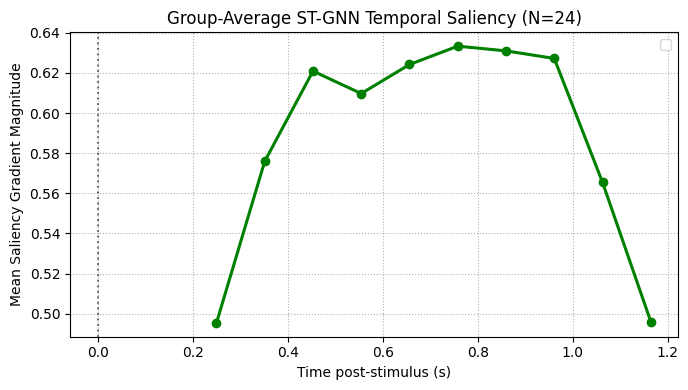

In [15]:
# Compute cohort-wide temporal saliency profiles
group_temp_saliencies = []
for sub in subject_ids:
    splits = list(temporal_stratified_splits(y[subjects == sub], train_cfg.n_splits))
    X_sub = X_graph[subjects == sub]
    y_sub = y[subjects == sub]
    sub_temp = []

    for fold, (train_idx, test_idx) in enumerate(splits, start=1):
        _, X_test = standardize_train_test(X_sub[train_idx], X_sub[test_idx])
        y_test = y_sub[test_idx]

        weights_path = paths.cache_dir / f"{TASK_TAG}_sub{sub}_fold{fold}.pt"
        if weights_path.exists():
            model = make_model().to(device)
            model.load_state_dict(torch.load(weights_path, map_location=device))
            model.eval()

            idx_c1 = y_test == 1
            if np.any(idx_c1):
                X_tensor = torch.from_numpy(X_test[idx_c1]).to(device)
                X_tensor.requires_grad_()
                logits = model(X_tensor)
                probs_out = torch.softmax(logits, dim=1)
                score = probs_out[:, 1].sum()
                model.zero_grad()
                score.backward()
                saliency = X_tensor.grad.abs().cpu().numpy()
                sub_temp.append(saliency.mean(axis=0))

    if sub_temp:
        mean_sub = np.mean(sub_temp, axis=0)
        mean_sub_norm = mean_sub / np.max(mean_sub) if np.max(mean_sub) > 0 else mean_sub
        group_temp_saliencies.append(mean_sub_norm.mean(axis=(1, 2)))

if group_temp_saliencies:
    group_temp_saliencies = np.array(group_temp_saliencies)
    mean_temp_sal = np.mean(group_temp_saliencies, axis=0)

    plt.figure(figsize=(7, 4))
    plt.plot(window_centers, mean_temp_sal, "o-", color="green", linewidth=2.2)
    plt.axvline(0.0, color="black", alpha=0.5, linestyle=":")
    plt.title(f"Group-Average ST-GNN Temporal Saliency (N={len(group_temp_saliencies)})")
    plt.xlabel("Time post-stimulus (s)")
    plt.ylabel("Mean Saliency Gradient Magnitude")
    plt.legend()
    plt.grid(True, linestyle=":")
    plt.tight_layout()
    plt.savefig(paths.figures_dir / f"group_saliency_temporal_{TASK_TAG}.png", dpi=200, bbox_inches="tight")
    plt.show()